# FCC-ee HEB V26.2 — IDDEFIX HOM-only RF + collider-derived damper stripline kickers

**Updated from:** `HEB_V26_2_native_PyWIT_Model_and_budget_V26_2_EXPORTS.ipynb` (uploaded notebook).

This notebook uses your **locally installed, editable** `fcc_ee_booster_pywit_model` and native `pywit` classes. It preserves RW, wiggler, extraction kicker, BPM, and bellows sources, and makes **two changes**:

1. **Longitudinal RF:** replace the original CST 3 mm RF impedance with the **per-cavity full IDDEFIX HOM1+HOM2+HOM3 impedance**, excluding the actively controlled 800 MHz accelerating fundamental. The original transverse RF impedances are unchanged; no transverse IDDEFIX fit is available.
2. **New `Damper` element:** import `Z_long_stripkickers26.txt`, `Z_dipx_stripkickers26.txt`, and `Z_dipy_stripkickers26.txt` as a **separate** longitudinal and dipolar stripline-kicker family. Assume, **provisionally**, that the imported collider files represent the sum of 12 identical kickers, and scale to an adjustable HEB count. The existing `Kicker` element remains the *extraction kicker*.

The original `W_stripkickers26.txt` is loaded for **optional reference/diagnostics**; its driving bunch definition and exact normalization must be established before using it as the 0.4 mm HEB wake. Instead, the damper 0.4 mm wake is reconstructed from the three complex impedance files.

**Critical:** the three-HOM model is a *partial* longitudinal RF model; it excludes other HOMs, the CST broadband remainder, and the closed-loop FM response. This notebook generates a **provisional V26.2 scenario** rather than silently overwriting the original published budget.

Exports are written to new folders:
- `data/total/v26_2_HOMonly_Damper_N2/` (N changes with `N_HEB_DAMPERS`), including signed impedance, adaptive longitudinal budget, 0.4 mm wakes, inventory and tracking wake.
- `data/damper_kickers/HEB_v26_2_stripkickers26_N2/` for the scaled damper contribution.
- `figures/v26_2_HOMonly_Damper_N2/` for plots.

No original CST or collider files are overwritten. The raw `stripkickers26` model may have an electrode aperture different from the nominal HEB 30 mm pipe radius: this scenario does **not** correct for that geometry difference.

In [2]:
from pathlib import Path
import importlib
import json
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import c as speed_of_light
from IPython.display import display

from pywit.component import Component
from pywit.element import Element
from pywit.model import Model
from fcc_ee_booster_pywit_model import HEBModel
from fcc_ee_booster_pywit_model.package_paths import base_dir

print('Using HEBModel:', HEBModel.__module__)
assert HEBModel.__module__.endswith('.heb_gold_tl'), (
    'The V26.2 native HEBModel/heb_gold_tl.py is required. Install the updated '
    'HEB model in your local editable PyWIT checkout, then restart the kernel.'
)
DATA = Path(base_dir).resolve() / 'data'
PROJECT_ROOT = DATA.parent.parent
print('Package data root:', DATA)
print('Git project root:', PROJECT_ROOT)
if not (DATA/'rf_cavities').is_dir():
    raise FileNotFoundError(f'Missing local data/rf_cavities folder: {DATA}')

Using HEBModel: fcc_ee_booster_pywit_model.heb_gold_tl
Package data root: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data
Git project root: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model


## 1. Settings — editable before Run All

**Baseline:** two 1 m stripline units sharing one installation *region*, but **no actual HEB location is assigned**. Therefore transverse beta factors default to unity (ring average). Provide one longitudinal ring position `s_m` **per unit** to use the V26.2 TFS beta functions; repetition of a position is allowed when two units are colocated.

The `/12` normalization is a **working assumption**, not verified by the original CST project's per-unit normalization. Confirm it with the collider impedance-model authors before promoting these exports to the official HEB budget.

In [3]:
# ===== Adjustable installation / impedance assumptions =====
N_HEB_DAMPERS = 2                   # provisional HEB count: try 1, 2, 4
N_COLLIDER_STRIPLINES = 12          # assumed number already summed in GitHub Z_*stripkickers26
ACTIVE_LENGTH_PER_DAMPER_M = 1.0   # collider concept; not a separate impedance multiplier
# Use None until positions are established, or e.g. [1234.0, 1234.0] for two units.
DAMPER_S_POSITIONS_M = None

# Native HEB V26.2 settings, retained from the uploaded notebook
ENERGY_EV = 20e9
OPTICS_TFS = DATA/'optics'/'v26_2'/'heb_ring_z.tfs'
KICKER_ARCHIVE = None
WIGGLER_CACHE = None
FLATCHAMBER_EXE = None

# Numerical grids. The 10 MHz budget is for browsing/plots, not HOM loss factors.
F_BUDGET = np.linspace(0.0, 50e9, 5001)
WAKE_SIGMA_M = 0.4e-3
WAKE_FMAX_HZ = 10e12
WAKE_DF_HZ = 100e6
WAKE_WINDOW_MM = (-3.0, 20.0)

SAVE_PROJECT_DATA = True
SAVE_FIGURES = True
CASE_TAG = f'v26_2_HOMonly_Damper_N{N_HEB_DAMPERS}'
TOTAL_EXPORT_DIR = DATA/'total'/CASE_TAG
DAMPER_EXPORT_DIR = DATA/'damper_kickers'/f'HEB_v26_2_stripkickers26_N{N_HEB_DAMPERS}'
FIGURES_DIR = PROJECT_ROOT/'figures'/CASE_TAG

RF_IMP_FILENAME = 'Z_single_rf_cavity_long_IDDEFIX_HOM_only_ADAPTIVE_0to50GHz.txt'
RF_WAKE_FILENAME = 'W_single_rf_cavity_long_IDDEFIX_HOM_only_sigma0.4mm.txt'
RF_IMP_PATH = DATA/'rf_cavities'/RF_IMP_FILENAME
RF_WAKE_PATH = DATA/'rf_cavities'/RF_WAKE_FILENAME

DAMPER_FILENAMES = {
    'long':'Z_long_stripkickers26.txt',
    'x':'Z_dipx_stripkickers26.txt',
    'y':'Z_dipy_stripkickers26.txt',
}
DAMPER_WAKE_FILENAME = 'W_stripkickers26.txt'

if N_HEB_DAMPERS < 1 or N_COLLIDER_STRIPLINES < 1:
    raise ValueError('Kicker counts must be >=1')
if not OPTICS_TFS.is_file():
    raise FileNotFoundError(f'V26.2 optics TFS missing: {OPTICS_TFS}')
for path in (RF_IMP_PATH, RF_WAKE_PATH):
    if not path.is_file():
        raise FileNotFoundError(f'Run the prior IDDEFIX Option 1 export notebook first: {path}')
if SAVE_PROJECT_DATA and not (PROJECT_ROOT/'.git').is_dir():
    raise RuntimeError('The HEB package must be imported from an editable local Git checkout, not site-packages.')

print('Candidate tag:', CASE_TAG)
print('Longitudinal RF impedance:', RF_IMP_PATH)
print('RF 0.4 mm wake:', RF_WAKE_PATH)
print('Number of HEB stripline units:', N_HEB_DAMPERS)
print('Assumed collider unit count in source:', N_COLLIDER_STRIPLINES)
print('Beta positions:', DAMPER_S_POSITIONS_M or 'UNKNOWN — unity beta weighting (provisional)')

Candidate tag: v26_2_HOMonly_Damper_N2
Longitudinal RF impedance: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/Z_single_rf_cavity_long_IDDEFIX_HOM_only_ADAPTIVE_0to50GHz.txt
RF 0.4 mm wake: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/W_single_rf_cavity_long_IDDEFIX_HOM_only_sigma0.4mm.txt
Number of HEB stripline units: 2
Assumed collider unit count in source: 12
Beta positions: UNKNOWN — unity beta weighting (provisional)


## 2. Read the collider stripline source data (no extra length multiplication)

The published collider `Z_*stripkickers26.txt` files are **device-family complex impedances** in `Frequency[GHz], ReZ, ImZ`; the `/12` factor below converts an assumed 12-unit family to a per-unit surrogate. The active length is **not** multiplied again. Source files can be directly under `data/` or nested under `data/damper_kickers`, `data/kickers`, etc.

In [4]:
# Native source arrays stay untouched. Refuse ambiguous duplicate filenames.
def find_unique_source(filename):
    candidates = [p for p in DATA.rglob(filename) if p.is_file()]
    if not candidates:
        raise FileNotFoundError(
            f'{filename} not found under {DATA}. Put the four stripkickers26 files inside data/ '
            'or any of its subfolders.'
        )
    if len(candidates) > 1:
        raise RuntimeError(f'Multiple copies of {filename}; choose one explicitly: {candidates}')
    return candidates[0]


def read_complex_impedance_table(path):
    dat = np.loadtxt(path, comments='#', usecols=(0,1,2), ndmin=2)
    if len(dat) < 3 or not np.all(np.isfinite(dat)):
        raise ValueError(f'Bad/non-finite impedance source: {path}')
    freq_ghz, re, im = dat.T
    if np.any(np.diff(freq_ghz) <= 0) or freq_ghz[0] < 0:
        raise ValueError(f'Frequency axis must be strictly increasing GHz: {path}')
    if not 0 < freq_ghz[-1] <= 1e5:
        raise ValueError(f'Implausible GHz frequency range: {path}')
    return freq_ghz*1e9, re+1j*im

DAMPER_PATHS = {pl: find_unique_source(fname) for pl,fname in DAMPER_FILENAMES.items()}
STRIPLINE_DATA = {pl:read_complex_impedance_table(path) for pl,path in DAMPER_PATHS.items()}
RF_FREQ, RF_Z_SINGLE = read_complex_impedance_table(RF_IMP_PATH)

if RF_FREQ[-1] < 49.999e9:
    raise ValueError('The IDDEFIX HOM-only input must span the full 0–50 GHz budget.')
if np.min(RF_Z_SINGLE.real) < -1e-7:
    raise ValueError('HOM-only RF source contains unexpected negative Re Z; inspect IDDEFIX export.')

for pl,(f,z) in STRIPLINE_DATA.items():
    print(f'{pl:4s}: {len(f):>7,d} points, {f[0]/1e9:.4g}–{f[-1]/1e9:.4g} GHz; {DAMPER_PATHS[pl]}')
print(f'RF HOM-only: {len(RF_FREQ):,d} points; max Re Z = {RF_Z_SINGLE.real.max():.5g} Ω/cavity')

# Optional source wake: provided as time[ns], Wlong[V/pC], Wx/Wy[V/(pC mm)],
# with possible additional quadrupole columns. It is NOT substituted into the
# 0.4 mm budget until its CST bunch sigma and normalization are independently known.
try:
    DAMPER_ORIGINAL_WAKE_PATH = find_unique_source(DAMPER_WAKE_FILENAME)
    DAMPER_ORIGINAL_WAKE = np.loadtxt(DAMPER_ORIGINAL_WAKE_PATH,comments='#',skiprows=1,ndmin=2)
    if DAMPER_ORIGINAL_WAKE.shape[1] not in (4,6):
        warnings.warn('W_stripkickers26 has unexpected column count; not used in budget')
        DAMPER_ORIGINAL_WAKE = None
    else:
        print('Reference collider wake loaded (diagnostics only):', DAMPER_ORIGINAL_WAKE_PATH,
              'shape=',DAMPER_ORIGINAL_WAKE.shape)
except (FileNotFoundError, ValueError) as exc:
    DAMPER_ORIGINAL_WAKE_PATH = None
    DAMPER_ORIGINAL_WAKE = None
    warnings.warn(f'Optional source wake not loaded: {exc}')

long: 592,393 points, 0–50 GHz; /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/kickers/Z_long_stripkickers26.txt
x   : 592,393 points, 0–50 GHz; /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/kickers/Z_dipx_stripkickers26.txt
y   : 592,393 points, 0–50 GHz; /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/kickers/Z_dipy_stripkickers26.txt
RF HOM-only: 12,498 points; max Re Z = 87944 Ω/cavity
Reference collider wake loaded (diagnostics only): /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/kickers/W_stripkickers26.txt shape= (10001, 6)


## 3. Build the native V26.2 PyWIT model with the new longitudinal RF source

The original installed `HEBModel` expects the CST file name hard-coded in `heb_gold_tl.SOURCE_PATHS['RF']['long']`. Rather than altering any file on disk, temporarily replace this **in-memory configuration during construction**, then restore it in `finally`.

Thus **RF (longitudinal)** uses the adaptive IDDEFIX HOM-only table; **RF (x/y)** continues to use the existing CST dipolar files. Extraction-kicker normalization, ring resistive wall, wiggler, BPM and bellows stay unchanged.

In [5]:
heb_module = importlib.import_module(HEBModel.__module__)
old_rf_relative = heb_module.SOURCE_PATHS['RF']['long']
try:
    rf_relative = RF_IMP_PATH.relative_to(DATA).as_posix()
    heb_module.SOURCE_PATHS['RF']['long'] = rf_relative
    native_model = HEBModel(
        energy=ENERGY_EV,
        optics_filename=OPTICS_TFS,
        data_dir=DATA,
        n_rf=112,
        rf_name_hint='ac800',
        sigma_cu=5.8e7,
        sigma_neg=1e6,
        neg_t_m=150e-9,
        roughness_rq_m=0.3e-6,
        gold_reference_q=-2.1043,
        beam_pipe_radius_m=0.030,
        rw_fmax_hz=10e12,
        rw_nfreq=2801,
        kicker_length_m=4.18,
        kicker_reference_length_m=20.0,
        kicker_archive=KICKER_ARCHIVE,
        wigglers=10,
        wiggler_each_length_m=6.03,
        wiggler_beta_m=4.0,
        wiggler_cache=WIGGLER_CACHE,
        wiggler_iw2d_executable=FLATCHAMBER_EXE,
        n_bellows=10000,
        bellows_length_m=0.15,
    )
finally:
    heb_module.SOURCE_PATHS['RF']['long'] = old_rf_relative

assert len(native_model.elements) == 6, 'Expected six base PyWIT elements in V26.2'
print('Base native PyWIT elements:', [el.name for el in native_model.elements])
print('RF longitudinal source actually installed:',
      native_model.source_provenance.query("family == 'RF' and plane == 'long'")['path'].tolist())
assert native_model.source_provenance.query("family == 'RF' and plane == 'long'")['path'].iloc[0] == str(RF_IMP_PATH)

Base native PyWIT elements: ['RW', 'Wiggler', 'Kicker', 'RF', 'BPM', 'Bellows']
RF longitudinal source actually installed: ['/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/Z_single_rf_cavity_long_IDDEFIX_HOM_only_ADAPTIVE_0to50GHz.txt']


## 4. Beta weights and the seventh native PyWIT `Damper` element

No HEB kicker location is fabricated. If `DAMPER_S_POSITIONS_M=None`, the ring-average beta is used **provisionally**. If a list of positions is supplied, local beta functions are interpolated from the V26.2 lattice. The source is assumed to be the **unweighted summed collider impedance of 12 devices**. The stripline active length has already been represented in that source and is **not applied a second time**.

In [6]:
if DAMPER_S_POSITIONS_M is None:
    damper_locations = pd.DataFrame({
        'unit':np.arange(1,N_HEB_DAMPERS+1),
        's_m':np.full(N_HEB_DAMPERS,np.nan),
        'beta_x_m':np.full(N_HEB_DAMPERS,native_model.beta_x_avg),
        'beta_y_m':np.full(N_HEB_DAMPERS,native_model.beta_y_avg),
        'status':['unknown; ring-average beta assumption']*N_HEB_DAMPERS,
    })
else:
    ss=np.asarray(DAMPER_S_POSITIONS_M,float)
    if ss.shape!=(N_HEB_DAMPERS,) or not np.all(np.isfinite(ss)):
        raise ValueError('DAMPER_S_POSITIONS_M must list one finite position per HEB damper')
    optics = native_model.optics_table.sort_values('s_m').drop_duplicates('s_m')
    sopt = optics.s_m.to_numpy(float)
    if ss.min()<sopt.min() or ss.max()>sopt.max():
        raise ValueError('Damper position is outside available V26.2 TFS coordinates')
    damper_locations=pd.DataFrame({
        'unit':np.arange(1,N_HEB_DAMPERS+1),
        's_m':ss,
        'beta_x_m':np.interp(ss,sopt,optics.beta_x_m),
        'beta_y_m':np.interp(ss,sopt,optics.beta_y_m),
        'status':['provisional position; local V26.2 beta']*N_HEB_DAMPERS,
    })

DAMPER_WEIGHTS = {
    'long': N_HEB_DAMPERS/N_COLLIDER_STRIPLINES,
    'x':float(damper_locations.beta_x_m.sum()/native_model.beta_x_avg/N_COLLIDER_STRIPLINES),
    'y':float(damper_locations.beta_y_m.sum()/native_model.beta_y_avg/N_COLLIDER_STRIPLINES),
}


def interpolate_source(freq_src, z_src, freq_dest):
    # No extrapolation outside the source frequency support.
    fq=np.atleast_1d(np.asarray(freq_dest,float))
    return (np.interp(fq,freq_src,z_src.real,left=0.,right=0.)
            +1j*np.interp(fq,freq_src,z_src.imag,left=0.,right=0.))


def damper_impedance(plane, frequency_hz):
    freq_src,z_src=STRIPLINE_DATA[plane]
    scaled=interpolate_source(freq_src,z_src,frequency_hz)*DAMPER_WEIGHTS[plane]
    return scaled[0] if np.ndim(frequency_hz)==0 else scaled

# Both the six-component HEBModel and the seventh element use the reference
# betas and an effective PyWIT length of 1. The impedance arrays are already
# integrated and (for x/y) HEB beta-weighted.
damper_components=[]
for pl,component_plane,exps in [('long','z',(0,0)),('x','x',(1,0)),('y','y',(0,1))]:
    def zfun(frequency, which=pl):
        return damper_impedance(which,frequency)
    damper_components.append(Component(
        impedance=zfun,plane=component_plane,
        source_exponents=exps,test_exponents=(0,0),
        name=f'Damper_{pl}',
    ))

damper_element=Element(
    length=1.0,beta_x=native_model.beta_x_avg,beta_y=native_model.beta_y_avg,
    components=damper_components,name='Damper',
    description=f'Provisional HEB {N_HEB_DAMPERS} stripline damper(s); collider family / {N_COLLIDER_STRIPLINES}',
)
combined_pywit=Model(
    elements=list(native_model.elements)+[damper_element],
    lumped_betas=(native_model.beta_x_avg,native_model.beta_y_avg),
)

NATIVE_FAMILIES=('RW','Wiggler','Kicker','RF','BPM','Bellows')
FAMILIES=NATIVE_FAMILIES+('Damper',)
SHORTHAND={'long':'z0000','x':'x1000','y':'y0100'}
print('Combined native PyWIT:',[el.name for el in combined_pywit.elements])
print('Damper family weights: long, x, y =',DAMPER_WEIGHTS)
display(damper_locations)

Combined native PyWIT: ['RW', 'Wiggler', 'Kicker', 'RF', 'BPM', 'Bellows', 'Damper']
Damper family weights: long, x, y = {'long': 0.16666666666666666, 'x': 0.16666666666666666, 'y': 0.16666666666666666}


,unit,s_m,beta_x_m,beta_y_m,status
0,1,NaN,58.582443,68.973003,unknown; ring-average beta assumption
1,2,NaN,58.582443,68.973003,unknown; ring-average beta assumption


## 5. Signed impedance budget and checks against `PyWIT.Model.total`

The default 0–50 GHz grid has a **10 MHz step**, much larger than the intrinsic widths of our high-Q HOMs. It is still useful for the broad budget figures, but **cannot** be used to integrate their loss factors reliably. An **additional adaptive-frequency longitudinal total** will therefore be computed from the IDDEFIX grid.

In [7]:
def impedance_budget(plane, freq_hz):
    f=np.asarray(freq_hz,float)
    if np.any(np.diff(f)<=0):
        raise ValueError('Frequency axis must be strictly increasing')
    components={family:np.asarray(native_model.component_impedance(family,plane,f),complex)
                for family in NATIVE_FAMILIES}
    components['Damper']=np.asarray(damper_impedance(plane,f),complex)
    total=np.asarray(combined_pywit.total.get_component(SHORTHAND[plane]).impedance(f),complex)
    summed=sum(components.values())
    np.testing.assert_allclose(total,summed,rtol=1e-8,atol=1e-7,
        err_msg=f'PyWIT seven-component total inconsistent in {plane}')
    return pd.DataFrame({'frequency_GHz':f/1e9,
        **{f'{kind}_{family}':mapper(z) for family,z in {**components,'Total':total}.items()
           for kind,mapper in [('Re',np.real),('Im',np.imag)]}})

budget={pl:impedance_budget(pl,F_BUDGET) for pl in ('long','x','y')}
# The adaptive IDDEFIX grid already contains 10 MHz samples, but take a union
# for safety if that changes in a future export.
# Round to 1 Hz before merging: source GHz->Hz floating errors can otherwise
# create almost-duplicate 10MHz nodes that collapse on file export.
F_ADAPTIVE=np.unique(np.rint(np.r_[F_BUDGET,RF_FREQ]).astype(np.int64)).astype(float)
assert F_ADAPTIVE[-1] <= 50e9*1.00000001
budget_adaptive_long=impedance_budget('long',F_ADAPTIVE)

# HOM-only RF loss factor: integrate on the ADAPTIVE grid, not 10 MHz.
def loss_factor_from_signed_complex(f_hz,z,sigma_m):
    w=np.exp(-(2*np.pi*f_hz*sigma_m/speed_of_light)**2)
    from scipy.integrate import trapezoid
    return 2e-12*trapezoid(np.asarray(z).real*w,f_hz)

rf_kappa_per_cavity=loss_factor_from_signed_complex(RF_FREQ,RF_Z_SINGLE,4e-3)
rf_kappa_112=rf_kappa_per_cavity*native_model.n_rf
print(f'IDDEFIX HOM-only longitudinal RF, sigma=4 mm: {rf_kappa_per_cavity:.6f} V/pC/cavity; '
      f'{rf_kappa_112:.6f} V/pC for {native_model.n_rf} cavities')
print('0–50 GHz budget points:',len(F_BUDGET),'Adaptive longitudinal points:',len(F_ADAPTIVE))

for pl,table in budget.items():
    deficit=int(np.sum(table['Re_Total']<table['Re_RW'])) if pl=='long' else None
    print(pl,'signed table shape:',table.shape,
          ('total ReZ below RW at '+str(deficit)+' 10MHz points' if pl=='long' else ''))

IDDEFIX HOM-only longitudinal RF, sigma=4 mm: 0.245629 V/pC/cavity; 27.510394 V/pC for 112 cavities
0–50 GHz budget points: 5001 Adaptive longitudinal points: 12498
long signed table shape: (5001, 17) total ReZ below RW at 0 10MHz points
x signed table shape: (5001, 17) 
y signed table shape: (5001, 17) 


## 6. Impedance-budget figures (all seven families)

Filled log-area figures display only positive values greater than 1, **but signed values are never changed in the data**. Separate signed checks include the negative regions. The RF HOM peaks are better represented on the additional adaptive-frequency plot.

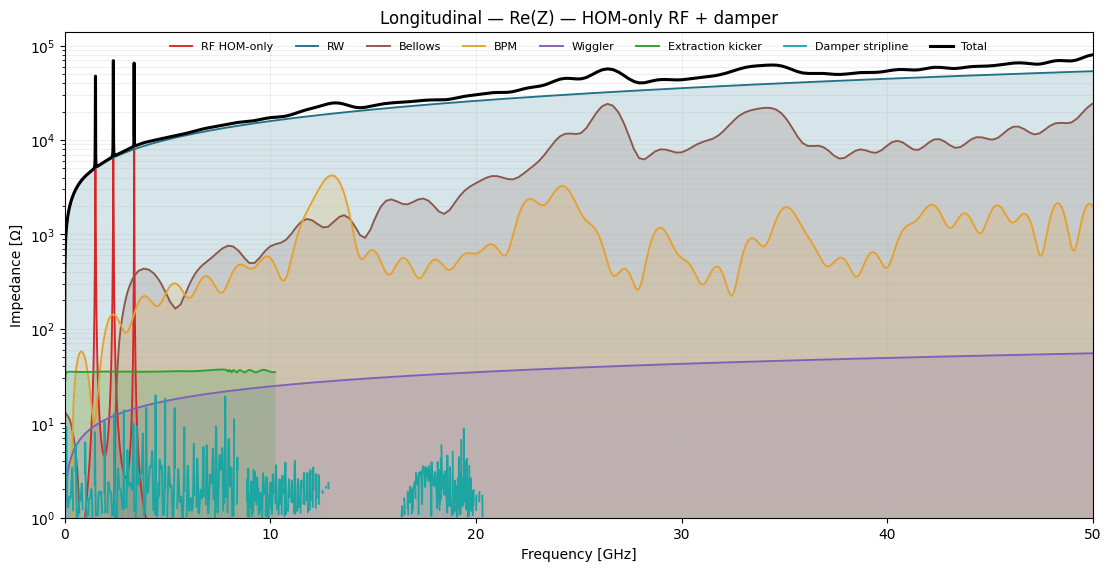

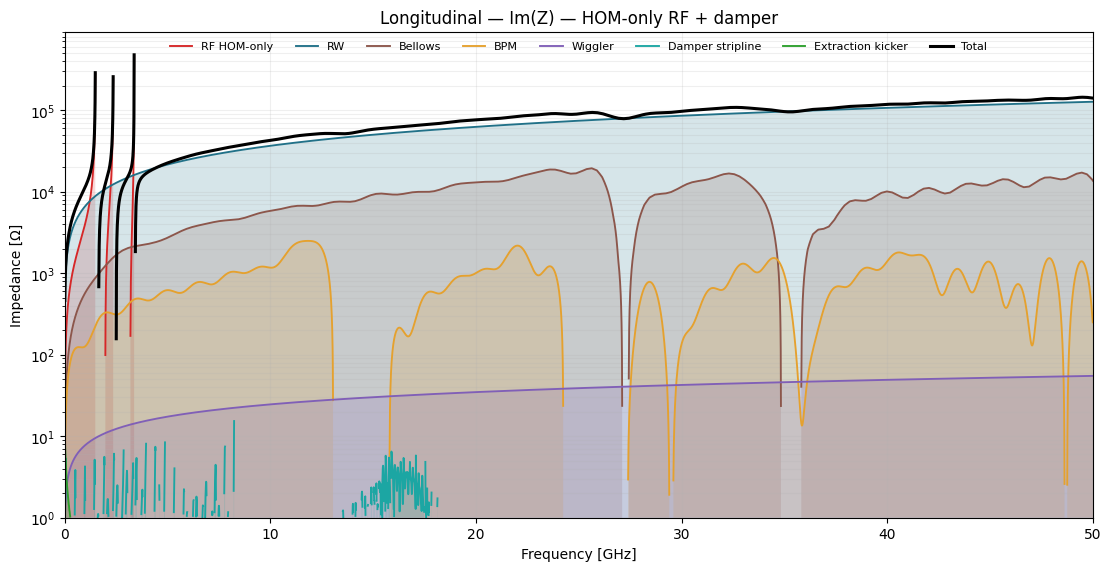

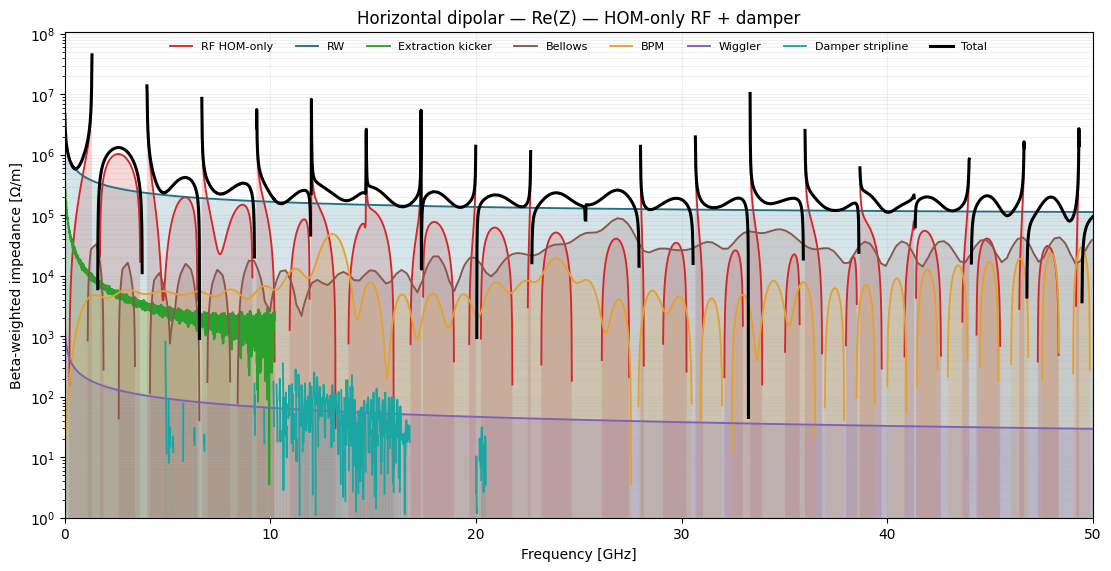

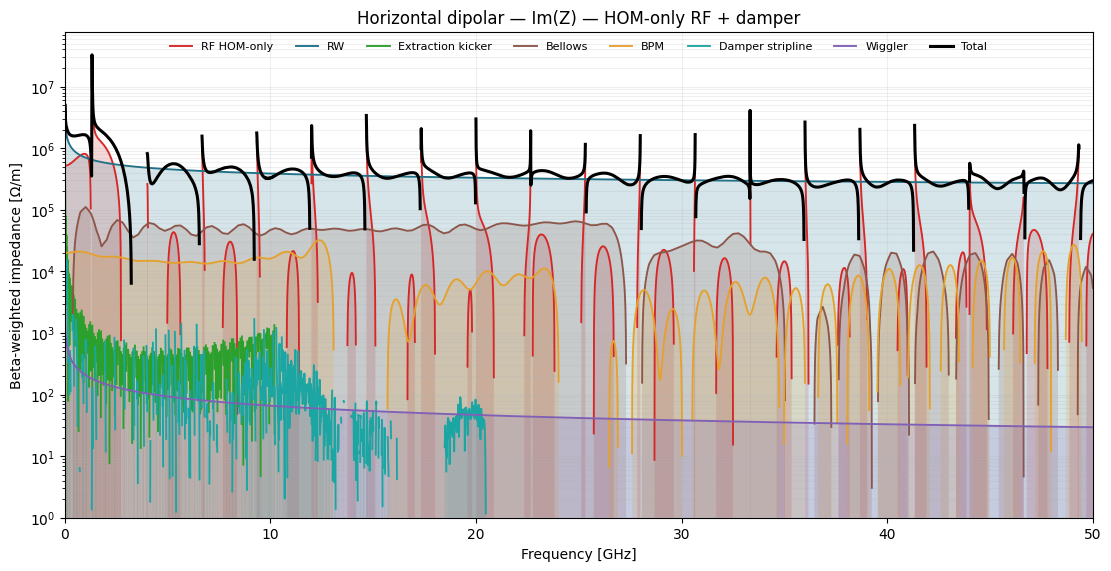

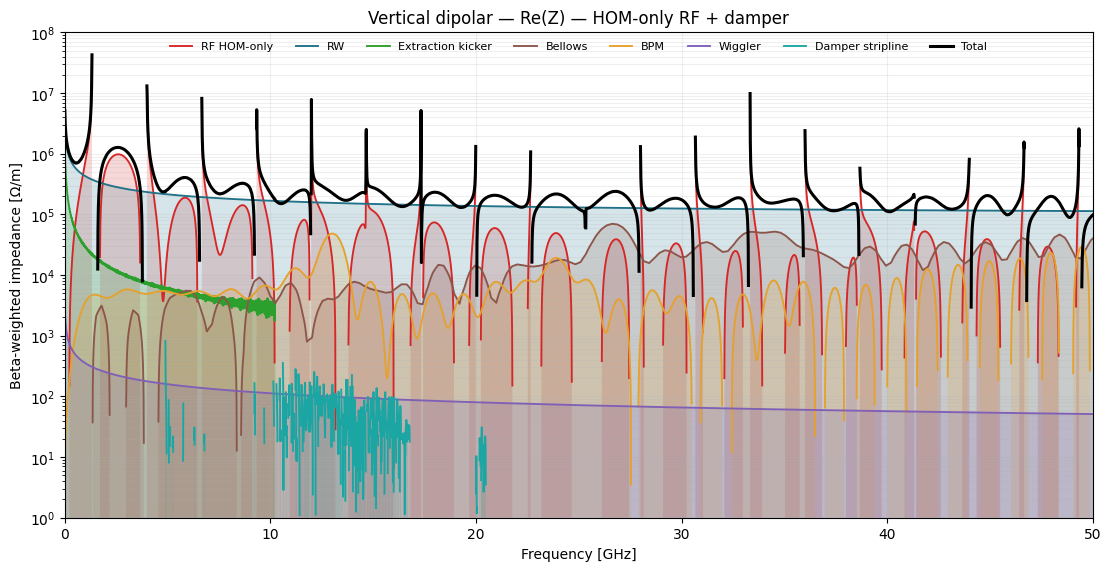

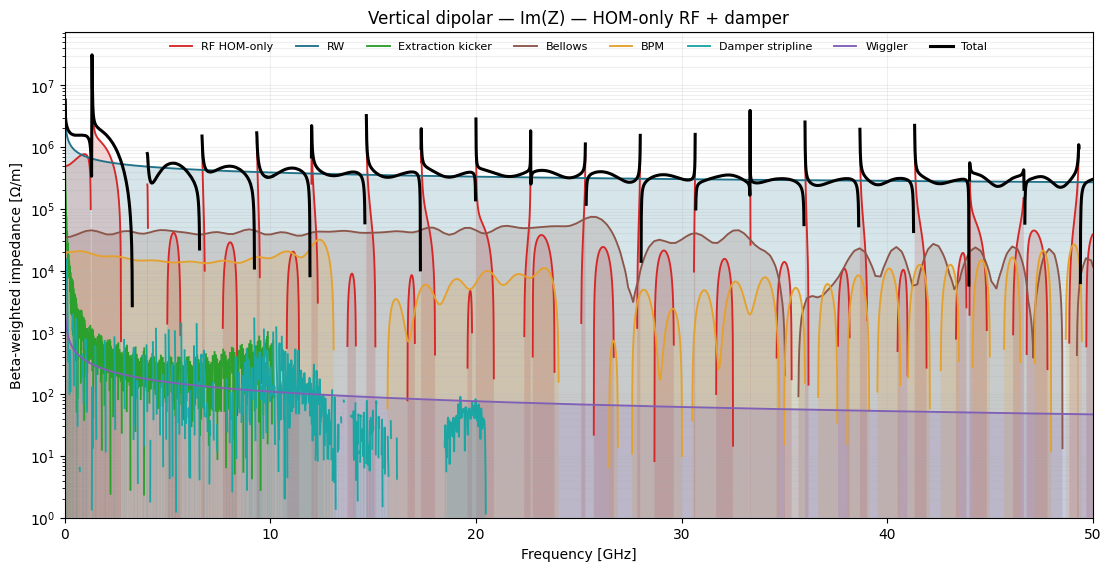

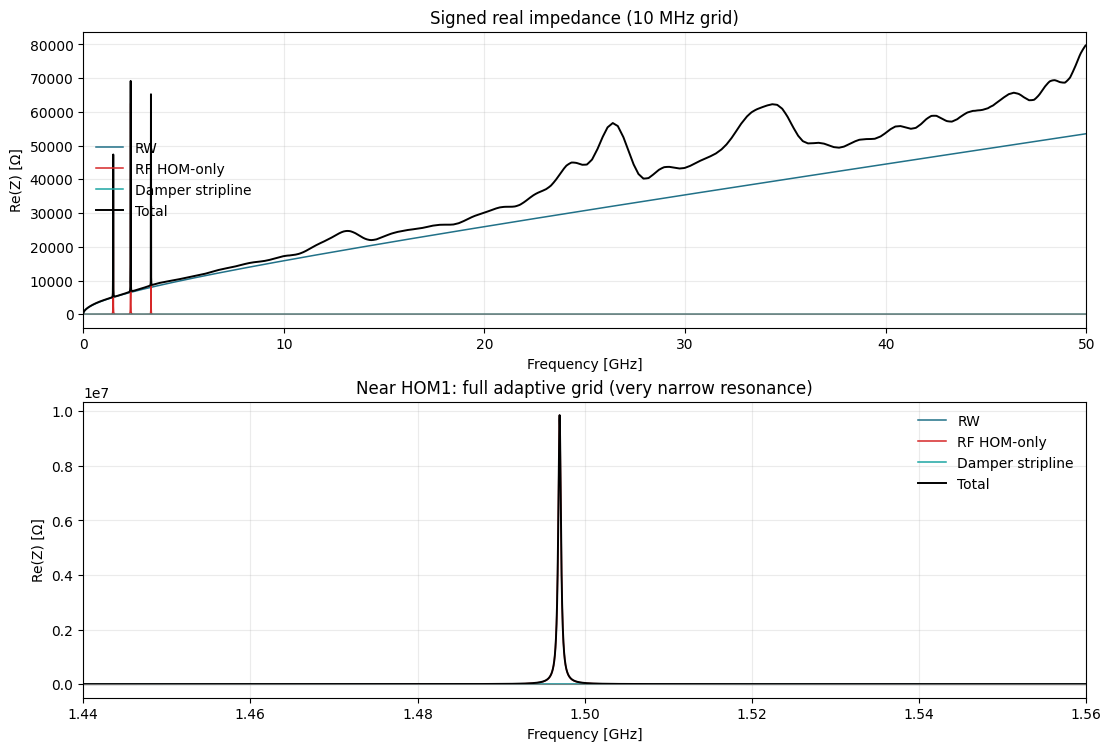

In [8]:
PLOT_LABELS={'Kicker':'Extraction kicker', 'Damper':'Damper stripline', 'RF':'RF HOM-only'}
colors={
 'RW':'#217188','Wiggler':'#805fb7','Kicker':'#2ca02c',
 'RF':'#d62728','BPM':'#e5a12e','Bellows':'#8c564b','Damper':'#1ca6a3',
}
plane_labels={'long':'Longitudinal','x':'Horizontal dipolar','y':'Vertical dipolar'}
plane_stems={'long':'long','x':'dipx','y':'dipy'}

def positive_for_log(x,floor=1.0):
    a=np.asarray(x,float)
    return np.where(np.isfinite(a)&(a>=floor),a,np.nan)

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True,exist_ok=True)

for pl in ('long','x','y'):
    t=budget[pl]
    f=t.frequency_GHz.to_numpy(float)
    for part in ('Re','Im'):
        fig,ax=plt.subplots(figsize=(11,5.6),layout='constrained')
        order=sorted(FAMILIES,
            key=lambda fam:float(np.nanmax(positive_for_log(t[f'{part}_{fam}'])))
                  if np.any(np.isfinite(positive_for_log(t[f'{part}_{fam}']))) else -np.inf,
            reverse=True)
        for family in order:
            y=positive_for_log(t[f'{part}_{family}'])
            if not np.any(np.isfinite(y)):continue
            ax.fill_between(f,1.,y,color=colors[family],alpha=.18,lw=0)
            ax.plot(f,y,lw=1.35,color=colors[family],label=PLOT_LABELS.get(family,family))
        ax.plot(f,positive_for_log(t[f'{part}_Total']),color='black',lw=2.2,label='Total')
        ax.set(xlabel='Frequency [GHz]',xlim=(0,50),
               ylabel='Impedance [Ω]' if pl=='long' else 'Beta-weighted impedance [Ω/m]',
               title=f'{plane_labels[pl]} — {part}(Z) — HOM-only RF + damper')
        ax.set_yscale('log');ax.set_ylim(bottom=1.)
        ax.grid(alpha=.2,which='both')
        ax.legend(loc='upper center',bbox_to_anchor=(.5,1.0),ncol=8,fontsize=8,frameon=False)
        if SAVE_FIGURES:
            fig.savefig(FIGURES_DIR/f'budget_{plane_stems[pl]}_{part.lower()}_{CASE_TAG}.png',
                        bbox_inches='tight',dpi=170)
        plt.show();plt.close(fig)

# Signed longitudinal diagnostic and RF HOM detail on adaptive frequency grid.
fig,axes=plt.subplots(2,1,figsize=(11,7.4),layout='constrained')
for ax,tab,lo,hi in [
        (axes[0],budget['long'],0.,50.),
        (axes[1],budget_adaptive_long,1.44,1.56)]:
    for family in ('RW','RF','Damper'):
        ax.plot(tab.frequency_GHz,tab[f'Re_{family}'],label=PLOT_LABELS.get(family,family),
                color=colors[family],lw=1.1)
    ax.plot(tab.frequency_GHz,tab['Re_Total'],color='black',lw=1.4,label='Total')
    ax.axhline(0,color='grey',lw=.6)
    ax.set(xlim=(lo,hi),ylabel='Re(Z) [Ω]',xlabel='Frequency [GHz]')
    ax.grid(alpha=.25);ax.legend(frameon=False)
axes[0].set_title('Signed real impedance (10 MHz grid)')
axes[1].set_title('Near HOM1: full adaptive grid (very narrow resonance)')
if SAVE_FIGURES:
    fig.savefig(FIGURES_DIR/f'signed_and_adaptive_{CASE_TAG}.png',dpi=170,bbox_inches='tight')
plt.show();plt.close(fig)

## 7. 0.4 mm Gaussian bunch wakes — avoid the narrow-HOM FFT sampling trap

Call the native V26.2 `bunch_wake_04mm` for RW, wiggler, extraction kicker, BPM, bellows, and the **unchanged transverse RF** sources. Because a 100 MHz frequency step cannot resolve the narrow longitudinal RF HOMs, **replace its longitudinal RF wake column** with the *already validated analytical full-HOM 0.4 mm wake* exported by our IDDEFIX notebook (112 cavities, CST longitudinal sign). Construct damper bunch wakes from its broadband complex Z on the same signed FFT convention used in `HEBModel`.

The `W_stripkickers26.txt` file is retained for a later independent comparison. Its underlying bunch sigma is not assumed to be 0.4 mm.

In [9]:
from scipy.constants import c as c_light

native_wakes=native_model.bunch_wake_04mm(
    sigma_z_m=WAKE_SIGMA_M,
    fmax_hz=WAKE_FMAX_HZ,
    df_hz=WAKE_DF_HZ,
    s_window_mm=WAKE_WINDOW_MM,
    include_individual=True,
)
reference_s=np.asarray(native_wakes['s_mm'],float)

# Input is a FULL HOM-only Gaussian bunch potential in CST longitudinal sign;
# each row is per cavity V/pC and must be multiplied by 112 once.
rf_wake_arr=np.loadtxt(RF_WAKE_PATH,comments='#',usecols=(0,1),ndmin=2)
rf_s,rf_w=rf_wake_arr.T
if not np.all(np.diff(rf_s)>0) or not np.all(np.isfinite(rf_w)):
    raise ValueError('Bad IDDEFIX HOM-only 0.4mm wake source')
if rf_s[0] > reference_s[0] or rf_s[-1] < reference_s[-1]:
    raise ValueError('IDDEFIX RF wake does not cover the requested HEB wake window')
rf_0p4_ring=np.interp(reference_s,rf_s,rf_w)*native_model.n_rf

# Match the exact PyWIT HEBModel's irfft convention and unit multipliers.
# Entire damper is already beta-weighted; this calculation is NOT per m.
n=int(np.rint(WAKE_FMAX_HZ/WAKE_DF_HZ))
if n<1 or not np.isclose(n*WAKE_DF_HZ,WAKE_FMAX_HZ,rtol=1e-12):
    raise ValueError('WAKE_FMAX_HZ/WAKE_DF_HZ should be an integer')
f_fft=np.arange(n+1,dtype=float)*WAKE_DF_HZ
dt=1./(2*n*WAKE_DF_HZ)
s_full_mm=(np.arange(2*n)-n)*dt*c_light*1e3
mask=(s_full_mm>=WAKE_WINDOW_MM[0])&(s_full_mm<=WAKE_WINDOW_MM[1])
np.testing.assert_allclose(s_full_mm[mask],reference_s,rtol=0,atol=3e-9)
g=np.exp(-0.5*(2*np.pi*f_fft*WAKE_SIGMA_M/c_light)**2)

def damper_gaussian_wake(plane):
    z=np.asarray(damper_impedance(plane,f_fft),complex)
    spec=z*g if plane=='long' else -1j*z*g
    spec[0]=complex(spec[0].real,0)
    spec[-1]=complex(spec[-1].real,0)
    physical=np.fft.fftshift(np.fft.irfft(spec,n=2*n))/dt
    conv=-1e-12 if plane=='long' else 1e-15
    return physical[mask]*conv

wakes={'s_mm':reference_s}
for plane in ('long','x','y'):
    t=native_wakes[plane].copy()
    if plane=='long':
        t['RF']=rf_0p4_ring
    t['Damper']=damper_gaussian_wake(plane)
    t['Total']=sum(t[family].to_numpy(float) for family in FAMILIES)
    np.testing.assert_allclose(t['Total'],sum(t[fam] for fam in FAMILIES),rtol=1e-12,atol=1e-10)
    wakes[plane]=t
    print(plane,':',len(t),'wake points; RF source:',
          'analytical full-HOM potential' if plane=='long' else 'original CST transverse')

long : 1535 wake points; RF source: analytical full-HOM potential
x : 1535 wake points; RF source: original CST transverse
y : 1535 wake points; RF source: original CST transverse


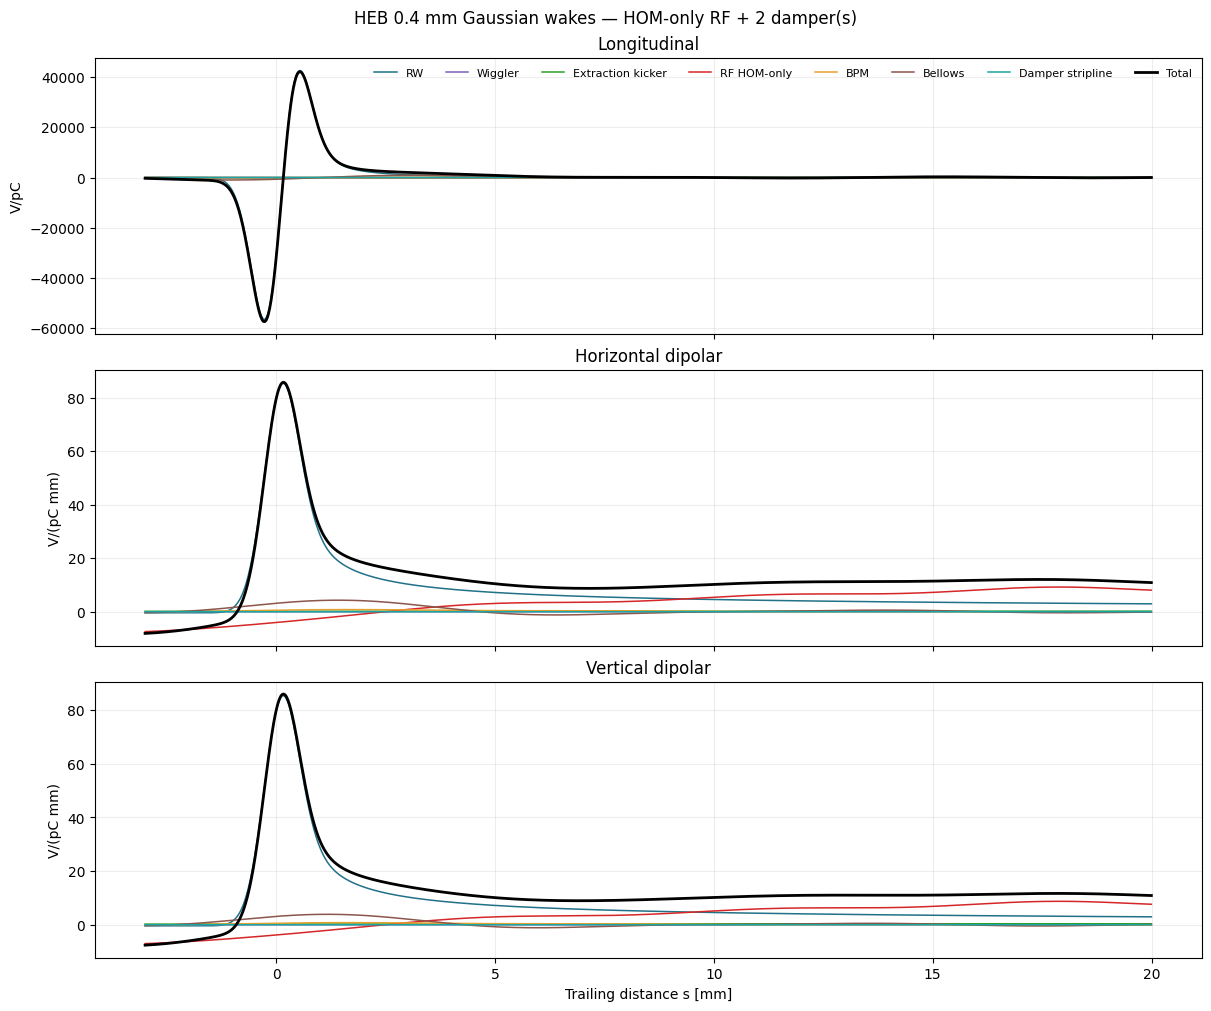

In [10]:
fig,ax=plt.subplots(3,1,figsize=(12,10),sharex=True,layout='constrained')
for i,plane in enumerate(('long','x','y')):
    t=wakes[plane]
    for family in FAMILIES:
        ax[i].plot(t.s_mm,t[family],label=PLOT_LABELS.get(family,family),color=colors[family],lw=1.1)
    ax[i].plot(t.s_mm,t.Total,label='Total',color='black',lw=2.0)
    ax[i].set_ylabel('V/pC' if plane=='long' else 'V/(pC mm)')
    ax[i].set_title(plane_labels[plane]);ax[i].grid(alpha=.22)
ax[-1].set_xlabel('Trailing distance s [mm]')
ax[0].legend(frameon=False,ncol=8,fontsize=8)
fig.suptitle(f'HEB 0.4 mm Gaussian wakes — HOM-only RF + {N_HEB_DAMPERS} damper(s)')
if SAVE_FIGURES:
    fig.savefig(FIGURES_DIR/f'wake_budget_{CASE_TAG}.png',dpi=170,bbox_inches='tight')
plt.show();plt.close(fig)

### Reference collider stripline wake — inspection only

If `W_stripkickers26.txt` was provided, show its three physical wake channels in the collider's published PyHEADTAIL units (time in ns, wake values in V/pC or V/(pC mm)), provisionally scaled by the same count/beta factors. **This source wake is not inserted into the 0.4 mm HEB budget** because its driving bunch definition has not yet been verified; the candidate wakes above were reconstructed from the complex impedance tables.

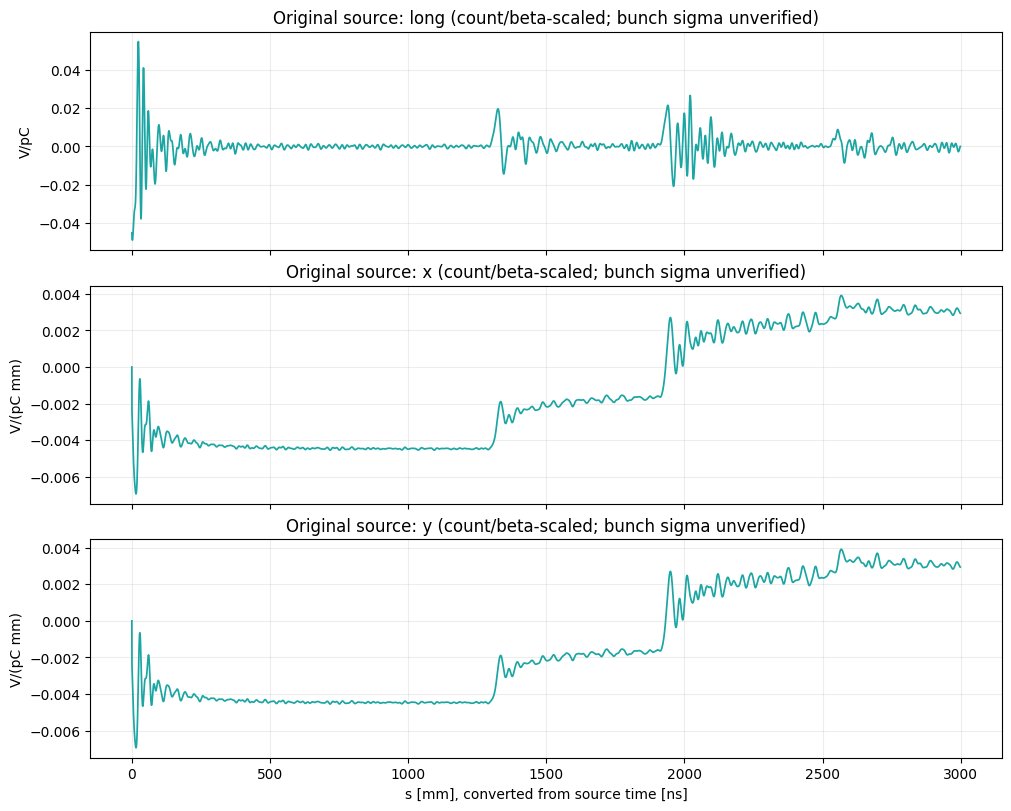

In [11]:
if DAMPER_ORIGINAL_WAKE is not None:
    raw=DAMPER_ORIGINAL_WAKE
    s_src_mm=raw[:,0]*speed_of_light*1e-6  # ns -> mm
    fig,axes=plt.subplots(3,1,figsize=(10,8),sharex=True,layout='constrained')
    for j,pl in enumerate(('long','x','y')):
        source_wake=raw[:,j+1]*DAMPER_WEIGHTS[pl]
        axes[j].plot(s_src_mm,source_wake,color=colors['Damper'],lw=1.25)
        axes[j].set_ylabel('V/pC' if pl=='long' else 'V/(pC mm)')
        axes[j].set_title(f'Original source: {pl} (count/beta-scaled; bunch sigma unverified)')
        axes[j].grid(alpha=.22)
    axes[-1].set_xlabel('s [mm], converted from source time [ns]')
    if SAVE_FIGURES:
        fig.savefig(FIGURES_DIR/f'collider_W_stripkickers26_reference_{CASE_TAG}.png',
                    dpi=160,bbox_inches='tight')
    plt.show();plt.close(fig)
else:
    print('No original collider W_stripkickers26 file available for separate diagnostics.')

## 8. Export candidate signed impedance/wake/metadata files

Only the newly versioned candidate folders are written. A separate **adaptive longitudinal total** retains the narrow HOM resonance resolution. All exported impedance rows use **GHz, ReZ, ImZ**; wake rows use **mm, wake**. All are **ring integrated**, not per element (except the original unchanged IDDEFIX file in `rf_cavities`).

In [12]:
def save_z(path,frequency_hz,z,description):
    path.parent.mkdir(parents=True,exist_ok=True)
    f=np.asarray(frequency_hz,float);v=np.asarray(z,complex)
    if not(np.all(np.diff(f)>0) and np.all(np.isfinite(v))):
        raise ValueError(f'Invalid source for saving {path}')
    np.savetxt(path,np.column_stack((f/1e9,v.real,v.imag)),fmt='%.14e',
               header=description+'\nfrequency_GHz ReZ ImZ')
    return path

def save_w(path,s_mm,w,description):
    path.parent.mkdir(parents=True,exist_ok=True)
    np.savetxt(path,np.column_stack((s_mm,np.asarray(w,float))),fmt='%.14e',
               header=description+'\ns_mm wake')
    return path

def display_relative_path(path):
    path=Path(path)
    try:return path.resolve().relative_to(PROJECT_ROOT.resolve()).as_posix()
    except ValueError:return '[external]/'+path.name

saved=[]
if SAVE_PROJECT_DATA:
    TOTAL_EXPORT_DIR.mkdir(parents=True,exist_ok=True)
    DAMPER_EXPORT_DIR.mkdir(parents=True,exist_ok=True)
    for pl,stem in plane_stems.items():
        t=budget[pl]
        fb=t.frequency_GHz.to_numpy(float)*1e9
        damper_z=t['Re_Damper'].to_numpy()+1j*t['Im_Damper'].to_numpy()
        total_z=t['Re_Total'].to_numpy()+1j*t['Im_Total'].to_numpy()
        saved.append(save_z(DAMPER_EXPORT_DIR/f'Z_{stem}_Damper_{CASE_TAG}.txt',
                      fb,damper_z,'HEB ring-integrated Damper; assumed collider 12-unit source; HEB beta weights applied'))
        saved.append(save_z(TOTAL_EXPORT_DIR/f'Z_total_{stem}_{CASE_TAG}.txt',
                      fb,total_z,'HEB 7-family candidate total; longitudinal RF=IDDEFIX full HOM-only; 10MHz display grid'))
        t.to_csv(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_component_budget_{stem}.csv',index=False)
        saved.append(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_component_budget_{stem}.csv')
        w=wakes[pl]
        unit='V/pC' if pl=='long' else 'V/(pC mm)'
        saved.append(save_w(DAMPER_EXPORT_DIR/f'W_{stem}_Damper_sigma0p4mm_{CASE_TAG}.txt',
                      w.s_mm,w.Damper,'HEB Damper 0.4mm Gaussian wake; '+unit))
        saved.append(save_w(TOTAL_EXPORT_DIR/f'W_total_{stem}_sigma0p4mm_{CASE_TAG}.txt',
                      w.s_mm,w.Total,'HEB 7-family 0.4mm Gaussian wake; '+unit))
        w.to_csv(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_component_wakes_{stem}_sigma0p4mm.csv',index=False)
        saved.append(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_component_wakes_{stem}_sigma0p4mm.csv')

    tl=budget_adaptive_long
    saved.append(save_z(TOTAL_EXPORT_DIR/f'Z_total_long_{CASE_TAG}_ADAPTIVE_0to50GHz.txt',
            tl.frequency_GHz.to_numpy(float)*1e9,
            tl.Re_Total.to_numpy()+1j*tl.Im_Total.to_numpy(),
            'HEB total longitudinal 0-50GHz on IDDEFIX-adaptive union grid; narrow HOMs preserved'))
    tl.to_csv(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_adaptive_long_budget.csv',index=False)
    saved.append(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_adaptive_long_budget.csv')

    inventory=pd.concat([native_model.inventory,
             pd.DataFrame([{'component':'Damper','count':N_HEB_DAMPERS,
             'physical_length_m':N_HEB_DAMPERS*ACTIVE_LENGTH_PER_DAMPER_M,
             'location_status':'provisional; '+('unknown' if DAMPER_S_POSITIONS_M is None else 'TFS positions') }])],
             ignore_index=True)
    inventory.to_csv(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_inventory.csv',index=False)
    saved.append(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_inventory.csv')
    damper_locations.to_csv(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_Damper_locations.csv',index=False)
    saved.append(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_Damper_locations.csv')

    provenance=native_model.source_provenance.copy()
    provenance['path']=provenance['path'].map(display_relative_path)
    damper_provenance=pd.DataFrame([{
       'family':'Damper','plane':pl,'path':display_relative_path(DAMPER_PATHS[pl]),
       'normalization':f'Assumed collider system/{N_COLLIDER_STRIPLINES} * HEB unit/beta sum (provisional)',
       'multiplier':DAMPER_WEIGHTS[pl],'input_fmax_ghz':STRIPLINE_DATA[pl][0][-1]/1e9,
    } for pl in ('long','x','y')])
    provenance=pd.concat([provenance,damper_provenance],ignore_index=True)
    provenance.to_csv(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_source_provenance.csv',index=False)
    saved.append(TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_source_provenance.csv')

    # PyHEADTAIL-compatible ECSV: same fields/time units as original native exporter.
    ss=wakes['s_mm'];t_ns=ss*1e6/speed_of_light
    headtail=TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_sigma0p4mm_PyHEADTAIL.ecsv'
    with headtail.open('w') as fh:
        fh.write('# %ECSV 1.0\n# ---\n# datatype:\n')
        for key in ('time','longitudinal','dipole_x','dipole_y'):
            fh.write(f'# - {{name: {key}, datatype: float64}}\n')
        fh.write('# meta: !!omap\n')
        fh.write(f'# - {{description: "HEB candidate; HOM-only RF; {N_HEB_DAMPERS} damper units; 0.4mm bunch"}}\n')
        fh.write('# schema: astropy-2.0\n')
        fh.write('time longitudinal dipole_x dipole_y\n')
        for row in zip(t_ns,wakes['long'].Total,wakes['x'].Total,wakes['y'].Total):
            fh.write(' '.join(f'{float(v):.14e}' for v in row)+'\n')
    saved.append(headtail)

    manifest={
       'description':'Provisional V26.2 HEB: IDDEFIX full HOM-only longitudinal RF + collider-derived stripline damper',
       'based_on':'HEB_V26_2_native_PyWIT_Model_and_budget_V26_2_EXPORTS.ipynb',
       'date_utc':datetime.now(timezone.utc).isoformat(),
       'RF_long_source':display_relative_path(RF_IMP_PATH),
       'RF_long_bunch_wake_source':display_relative_path(RF_WAKE_PATH),
       'RF_long_components':'full HOM1, HOM2, HOM3; 800MHz fundamental and broadband omitted',
       'RF_transverse':'original CST x/y RF files unchanged',
       'stripline_source_files':{pl:display_relative_path(p) for pl,p in DAMPER_PATHS.items()},
       'stripline_source_wake_reference':None if DAMPER_ORIGINAL_WAKE_PATH is None else display_relative_path(DAMPER_ORIGINAL_WAKE_PATH),
       'stripline_wake_reference_used_in_budget':False,
       'assumption_Coll_ring_impedance_already_integrates_12':True,
       'assumed_coll_units':N_COLLIDER_STRIPLINES,'HEB_damper_count':N_HEB_DAMPERS,
       'active_m_per_kicker':ACTIVE_LENGTH_PER_DAMPER_M,
       'HEB_damper_positions':None if DAMPER_S_POSITIONS_M is None else list(DAMPER_S_POSITIONS_M),
       'damper_weights':DAMPER_WEIGHTS,
       'warning_normalization':'Collider per-unit extraction by /12 remains to be confirmed with original CST authors',
       'wake_sigma_m':WAKE_SIGMA_M,'wake_df_Hz_for_nonRF_and_Damper':WAKE_DF_HZ,
       'RF_wake_method':'direct analytical HOM-only 0.4 mm bunch potential file; no coarse RF irfft',
       'RF_loss_factor_4mm_V_per_pC_112cav':rf_kappa_112,
       'frequency_units':'GHz','impedance_units_long':'Ohm','impedance_units_dipoles':'Ohm/m',
       'wake_units_long':'V/pC','wake_units_dipoles':'V/pC/mm',
       'adaptive_long_budget_points':len(F_ADAPTIVE),
       'saved_files':[display_relative_path(p) for p in saved],
    }
    man=TOTAL_EXPORT_DIR/f'HEB_{CASE_TAG}_EXPORT_MANIFEST.json'
    man.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    saved.append(man)
    print(f'Saved {len(saved)} scenario files under {TOTAL_EXPORT_DIR} and {DAMPER_EXPORT_DIR}')
    display(pd.DataFrame({'File':[display_relative_path(x) for x in saved]}))
else:
    print('SAVE_PROJECT_DATA=False; no export files created.')

Saved 25 scenario files under /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/total/v26_2_HOMonly_Damper_N2 and /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/damper_kickers/HEB_v26_2_stripkickers26_N2


,File
0,fcc_ee_booster_pywit_model/data/damper_kickers...
1,fcc_ee_booster_pywit_model/data/total/v26_2_HO...
2,fcc_ee_booster_pywit_model/data/total/v26_2_HO...
3,fcc_ee_booster_pywit_model/data/damper_kickers...
4,fcc_ee_booster_pywit_model/data/total/v26_2_HO...
5,fcc_ee_booster_pywit_model/data/total/v26_2_HO...
6,fcc_ee_booster_pywit_model/data/damper_kickers...
7,fcc_ee_booster_pywit_model/data/total/v26_2_HO...
8,fcc_ee_booster_pywit_model/data/total/v26_2_HO...
9,fcc_ee_booster_pywit_model/data/damper_kickers...


## 9. Interpretation, limits and next checks

- **Native PyWIT:** the total impedance is evaluated through `combined_pywit.total.get_component(...)` with seven Elements, and verified against the explicit sum at every exported frequency.
- **FM:** no 800 MHz longitudinal fundamental is included in the candidate RF HOM-only impedance. This does **not** assume that the operational closed-loop fundamental is zero; RF detuning and LLRF require a separate model for coupled-bunch studies.
- **RF broadband:** absent from the new longitudinal RF input. The three-HOM model is *not* equivalent to the original CST RF impedance (the σ=4 mm RF loss factor was substantially smaller in our earlier comparison). **Do not label it a complete RF impedance**.
- **RF transverse:** the original CST dipolar RF sources remain unchanged. Our IDDEFIX work did not provide validated transverse HOM-only files.
- **Damper:** `stripkickers26` comes from the collider **feedback/depolarizer stripline**, *not* the collider optimized extraction kicker. The existing extraction `Kicker` source stays unchanged.
- **Damper scaling:** the `/12` rule assumes the collider `Z_*stripkickers26.txt` files are an unweighted **twelve-unit total**. Confirm the exact CST-to-GitHub normalization and electrode aperture. The `N_HEB_DAMPERS=2` scenario is an explicit assumption, not an established HEB baseline.
- **Damper locations:** unknown by default; beta weights = ring average. For a location-aware budget, supply the position of each unit in `DAMPER_S_POSITIONS_M` and rerun.
- **Damper wake:** reconstructed from complex Z at the target σ=0.4 mm using the HEB convention. The original `W_stripkickers26.txt` is read only for later cross-check because the published bunch sigma/normalization was not verified here.
- **HOM sampling:** the 10 MHz plot grid misses the narrow HOM peaks. Use the additional **adaptive total longitudinal impedance**, and the analytical IDDEFIX 0.4 mm wake file in the candidate tracking wake.
- **Versioning:** exports are *provisional*, stored under new folders; the original `data/total/v26_2` and all source files remain untouched.

The notebook is intended for **Run All within your local editable PyWIT environment**. It cannot be executed against the real `stripkickers26` input here unless those source files and the entire locally installed HEB PyWIT model are available in the runtime.